<a href="https://colab.research.google.com/github/aziza-radouani/25007595-aziza-radouani-FIN3/blob/main/notebooks/projet_F3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F3 — Prévision de l'inflation

**Nom et prénom :** Aziza Radouani    **Code Apogée :** 25007595    **Groupe :** FIN3    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/aziza-radouani/25007595-aziza-radouani-FIN3

## 1. Sujet et problématique

- **Intérêt du sujet** : L'inflation influence les décisions des banques centrales (taux directeurs), des entreprises (prix, salaires, contrats) et des investisseurs (obligations, pouvoir d'achat). Savoir si des variables simples comme le chômage et le taux directeur aident à anticiper l'inflation à un an permet d'éclairer ces décisions.
- **Problématique** : Le chômage et le taux directeur permettent-ils de prévoir l'inflation annuelle 12 mois plus tard mieux que la dernière valeur observée ?
- **Objectif mesurable** : Obtenir, sur la période de test (janvier 2015 jusqu'à la fin des données), un RMSE inférieur d'au moins 10 % à celui de la référence « dernière valeur observée » (l'inflation dans 12 mois est supposée égale à l'inflation d'aujourd'hui).
- **Nature du problème** : Régression sur série temporelle, car la cible (l'inflation annuelle à t+12) est numérique et les observations sont ordonnées dans le temps.
- **Algorithme principal envisagé** : n° 2, Ridge (régression linéaire avec pénalisation L2).

## 2. Jeu de données
## 3. Exploration
## 4. Préparation
## 5. Algorithme
## 6. Protocole expérimental
## 7. Résultats
## 8. Analyse critique
## 9. Conclusion
## 10. Références et reproduction
## Déclaration des ressources et outils d'IA

In [27]:
!git clone https://github.com/aziza-radouani/25007595-aziza-radouani-FIN3.git
%cd 25007595-aziza-radouani-FIN3
!ls data/raw

Cloning into '25007595-aziza-radouani-FIN3'...
remote: Enumerating objects: 52, done.
remote: Counting objects: 100% (52/52), done.
remote: Compressing objects: 100% (43/43), done.
Receiving objects: 100% (52/52), 29.95 KiB | 14.98 MiB/s, done.
remote: Total 52 (delta 15), reused 0 (delta 0), pack-reused 0 (from 0)
Resolving deltas: 100% (15/15), done.
/content/25007595-aziza-radouani-FIN3/25007595-aziza-radouani-FIN3/25007595-aziza-radouani-FIN3
CPIAUCSL.csv  FEDFUNDS.csv  UNRATE.csv


In [28]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path

warnings.filterwarnings('ignore')
GRAINE = 42
RAW = Path('data/raw')

print('Python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1


In [29]:
series = ['CPIAUCSL', 'UNRATE', 'FEDFUNDS']
morceaux = []
for s in series:
    d = pd.read_csv(RAW / f'{s}.csv', index_col=0, parse_dates=True)
    morceaux.append(pd.to_numeric(d.iloc[:, 0], errors='coerce').rename(s))
df = pd.concat(morceaux, axis=1)

print('Dimensions :', df.shape)
print('Période :', df.index.min().date(), '->', df.index.max().date())
print('Fréquence :', pd.infer_freq(df.index))
print('Valeurs manquantes :'); print(df.isna().sum())
display(df.head()); display(df.tail())

Dimensions : (958, 3)
Période : 1947-01-01 -> 2026-10-01
Fréquence : MS
Valeurs manquantes :
CPIAUCSL     1
UNRATE      13
FEDFUNDS    90
dtype: int64


,CPIAUCSL,UNRATE,FEDFUNDS
observation_date,,,
1947-01-01,21.48,NaN,NaN
1947-02-01,21.62,NaN,NaN
1947-03-01,22.00,NaN,NaN
1947-04-01,22.00,NaN,NaN
1947-05-01,21.95,NaN,NaN


,CPIAUCSL,UNRATE,FEDFUNDS
observation_date,,,
2026-06-01,332.568,4.2,3.63
2026-07-01,332.813,4.1,3.63
2026-08-01,334.131,4.1,3.63
2026-09-01,336.298,4.2,3.75
2026-10-01,337.476,4.1,3.88


In [30]:
from IPython.display import Markdown

n = len(df)
debuts = {c: df[c].first_valid_index().strftime('%Y-%m') for c in df.columns}
pct = (df.isna().sum() / n * 100).round(1)

lacunes = []
for c in df.columns:
    apres = df.loc[df[c].first_valid_index():, c]
    for d in apres[apres.isna()].index:
        lacunes.append(c + ' (' + d.strftime('%Y-%m') + ')')
texte_lacunes = ', '.join(lacunes) if lacunes else 'aucune'

lignes = [
    "## 2. Jeu de données",
    "",
    "- **Source** : FRED (Federal Reserve Bank of St. Louis), trois séries mensuelles : CPIAUCSL, UNRATE et FEDFUNDS (https://fred.stlouisfed.org/series/CPIAUCSL, https://fred.stlouisfed.org/series/UNRATE, https://fred.stlouisfed.org/series/FEDFUNDS).",
    "- **Date d'extraction** : 17/11/2026",
    "- **Licence** : à confirmer sur la page de chaque série FRED (rubrique Copyright).",
    "- **Taille** : " + str(n) + " lignes × " + str(df.shape[1]) + " variables, période " + df.index.min().strftime('%Y-%m') + " à " + df.index.max().strftime('%Y-%m') + ", fréquence mensuelle.",
    "- **Unité d'observation** : un mois (une ligne = un mois).",
    "- **Variable cible** : l'inflation annuelle à t+12, construite à partir de CPIAUCSL (voir section 4).",
    "- **Adéquation** : la fiche du sujet propose le chômage et le taux directeur pour prévoir l'inflation ; les séries sont mensuelles et couvrent plusieurs décennies.",
    "- **Limites** : (1) les séries ne commencent pas à la même date (CPIAUCSL : " + debuts['CPIAUCSL'] + ", UNRATE : " + debuts['UNRATE'] + ", FEDFUNDS : " + debuts['FEDFUNDS'] + ") ; (2) valeurs manquantes après le début des séries : " + texte_lacunes + " ; (3) les séries sont révisées après publication (biais d'anticipation) ; (4) la relation entre chômage, taux directeur et inflation change selon les régimes (années 1970, 2008, 2021-2022).",
    "",
    "| Variable | Description | Type | Unité | Rôle | Manquants (%) |",
    "| --- | --- | --- | --- | --- | --- |",
    "| CPIAUCSL | Indice des prix à la consommation | numérique | indice | base de la cible | " + str(pct['CPIAUCSL']) + " |",
    "| UNRATE | Taux de chômage | numérique | % | explicative | " + str(pct['UNRATE']) + " |",
    "| FEDFUNDS | Taux directeur effectif de la Fed | numérique | % | explicative | " + str(pct['FEDFUNDS']) + " |",
]
texte = "\n".join(lignes)
print(texte)

## 2. Jeu de données

- **Source** : FRED (Federal Reserve Bank of St. Louis), trois séries mensuelles : CPIAUCSL, UNRATE et FEDFUNDS (https://fred.stlouisfed.org/series/CPIAUCSL, https://fred.stlouisfed.org/series/UNRATE, https://fred.stlouisfed.org/series/FEDFUNDS).
- **Date d'extraction** : 17/11/2026
- **Licence** : à confirmer sur la page de chaque série FRED (rubrique Copyright).
- **Taille** : 958 lignes × 3 variables, période 1947-01 à 2026-10, fréquence mensuelle.
- **Unité d'observation** : un mois (une ligne = un mois).
- **Variable cible** : l'inflation annuelle à t+12, construite à partir de CPIAUCSL (voir section 4).
- **Adéquation** : la fiche du sujet propose le chômage et le taux directeur pour prévoir l'inflation ; les séries sont mensuelles et couvrent plusieurs décennies.
- **Limites** : (1) les séries ne commencent pas à la même date (CPIAUCSL : 1947-01, UNRATE : 1948-01, FEDFUNDS : 1954-07) ; (2) valeurs manquantes après le début des séries : CPIAUCSL (2025-10), U

## 2. Jeu de données

- **Source** : FRED (Federal Reserve Bank of St. Louis), trois séries mensuelles : CPIAUCSL, UNRATE et FEDFUNDS (https://fred.stlouisfed.org/series/CPIAUCSL, https://fred.stlouisfed.org/series/UNRATE, https://fred.stlouisfed.org/series/FEDFUNDS).
- **Date d'extraction** : 17/11/2026
- **Licence** : à confirmer sur la page de chaque série FRED (rubrique Copyright).
- **Taille** : 958 lignes × 3 variables, période 1947-01 à 2026-10, fréquence mensuelle.
- **Unité d'observation** : un mois (une ligne = un mois).
- **Variable cible** : l'inflation annuelle à t+12, construite à partir de CPIAUCSL (voir section 4).
- **Adéquation** : la fiche du sujet propose le chômage et le taux directeur pour prévoir l'inflation ; les séries sont mensuelles et couvrent plusieurs décennies.
- **Limites** : (1) les séries ne commencent pas à la même date (CPIAUCSL : 1947-01, UNRATE : 1948-01, FEDFUNDS : 1954-07) ; (2) valeurs manquantes après le début des séries : CPIAUCSL (2025-10), UNRATE (2025-10) ; (3) les séries sont révisées après publication (biais d'anticipation) ; (4) la relation entre chômage, taux directeur et inflation change selon les régimes (années 1970, 2008, 2021-2022).

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
| --- | --- | --- | --- | --- | --- |
| CPIAUCSL | Indice des prix à la consommation | numérique | indice | base de la cible | 0.1 |
| UNRATE | Taux de chômage | numérique | % | explicative | 1.4 |
| FEDFUNDS | Taux directeur effectif de la Fed | numérique | % | explicative | 9.4 |


## 3. Exploration

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
from pandas_datareader import data as pdr

debut = "1954-07-01"
cpi = pdr.DataReader("CPIAUCSL", "fred", debut)
chom = pdr.DataReader("UNRATE", "fred", debut)
fed = pdr.DataReader("FEDFUNDS", "fred", debut)

df = pd.concat([cpi, chom, fed], axis=1)
df.columns = ["cpi", "chomage", "taux_directeur"]
df["inflation"] = df["cpi"].pct_change(12) * 100
df = df.dropna()
df.tail()

,cpi,chomage,taux_directeur,inflation
DATE,,,,
2026-06-01,332.568,4.2,3.63,3.463531
2026-07-01,332.813,4.1,3.63,3.303856
2026-08-01,334.131,4.1,3.63,3.353016
2026-09-01,336.298,4.2,3.75,3.717251
2026-10-01,337.476,4.1,3.88,4.080556


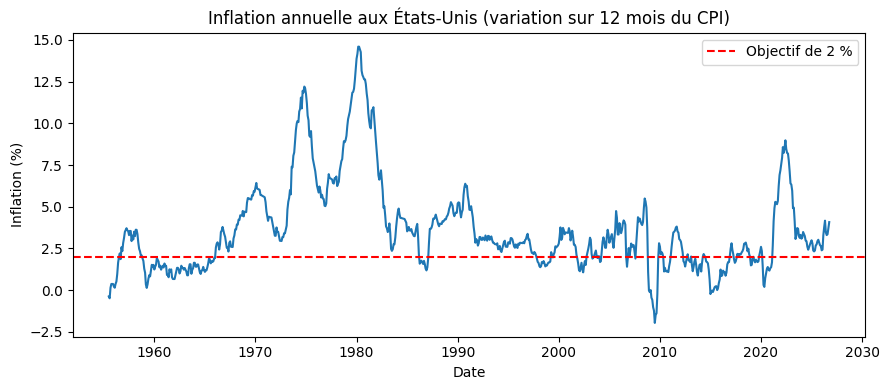

In [32]:
plt.figure(figsize=(9, 4))
plt.plot(df.index, df["inflation"])
plt.axhline(2, color="red", linestyle="--", label="Objectif de 2 %")
plt.title("Inflation annuelle aux États-Unis (variation sur 12 mois du CPI)")
plt.xlabel("Date")
plt.ylabel("Inflation (%)")
plt.legend()
plt.tight_layout()
plt.show()

**Description :** l'inflation reste faible (1 à 3 %) jusqu'au milieu des années 1960, puis s'envole : deux pics dans les années 1970 (environ 12 % en 1974 et 14,5 % en 1980, liés aux chocs pétroliers). Elle redescend dans les années 1980, reste modérée jusqu'en 2020, devient négative en 2009 (crise financière), puis remonte à environ 9 % en 2022 après la pandémie.

**Interprétation :** les années 1970 et 2022 sont les deux grandes périodes d'inflation élevée. Aujourd'hui l'inflation est d'environ 3 %, au-dessus de l'objectif de 2 %.

**Remarque :** la ligne rouge à 2 % est une référence. L'objectif officiel de la Fed date de 2012 et porte sur un autre indice (le PCE).

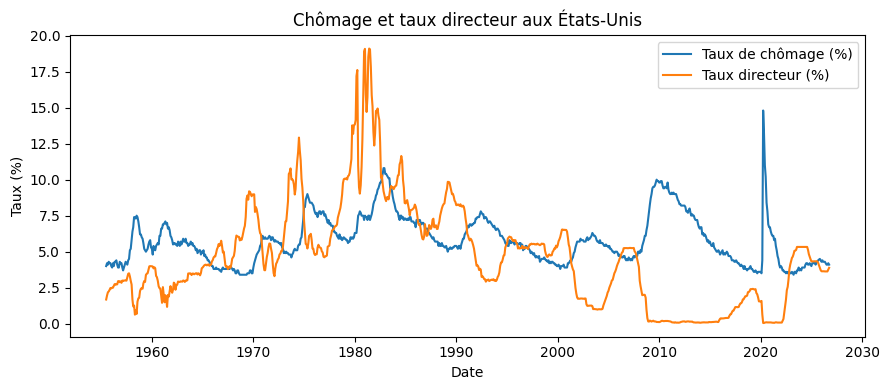

In [33]:
plt.figure(figsize=(9, 4))
plt.plot(df.index, df["chomage"], label="Taux de chômage (%)")
plt.plot(df.index, df["taux_directeur"], label="Taux directeur (%)")
plt.title("Chômage et taux directeur aux États-Unis")
plt.xlabel("Date")
plt.ylabel("Taux (%)")
plt.legend()
plt.tight_layout()
plt.show()

**Description :** le taux directeur atteint un pic d'environ 19-20 % en 1980-1981. Il est proche de 0 % après 2008 et en 2020-2021. Le chômage atteint environ 10,8 % en 1982, 10 % en 2010 et 14,8 % en avril 2020 (pandémie).

**Interprétation :** les années 1970 et 2022 sont les deux grandes périodes d'inflation élevée (maximum de 14,6 % en mars 1980). En octobre 2026, l'inflation est de 4,1 %, soit plus du double de l'objectif de 2 %.

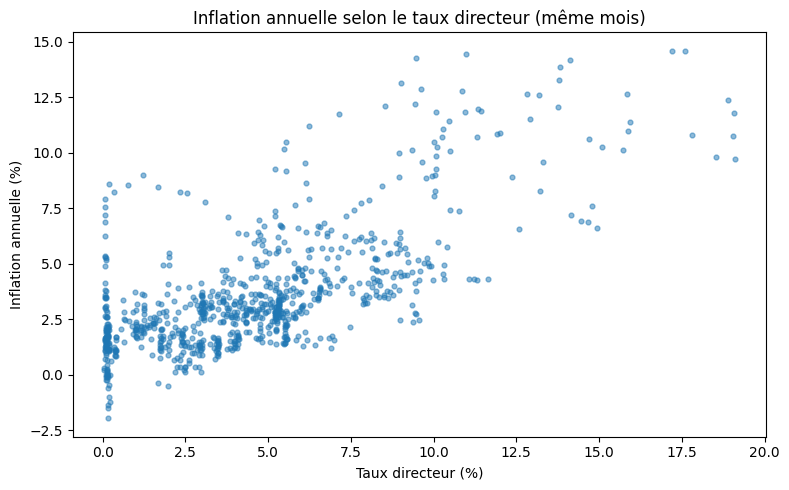

In [34]:
plt.figure(figsize=(8, 5))
plt.scatter(df["taux_directeur"], df["inflation"], alpha=0.5, s=12)
plt.xlabel("Taux directeur (%)")
plt.ylabel("Inflation annuelle (%)")
plt.title("Inflation annuelle selon le taux directeur (même mois)")
plt.tight_layout()
plt.show()

**Description :** le nuage de points montre une relation globalement positive : plus l'inflation est élevée, plus le taux directeur est élevé. Les points sont toutefois assez dispersés.

**Interprétation :** la politique de la Fed a été trop accommodante dans les années 1970 et en 2021, deux périodes suivies de fortes hausses de l'inflation. En octobre 2026, le taux réel est d'environ −0,2 % : la politique est donc légèrement accommodante, malgré une inflation au-dessus de l'objectif.

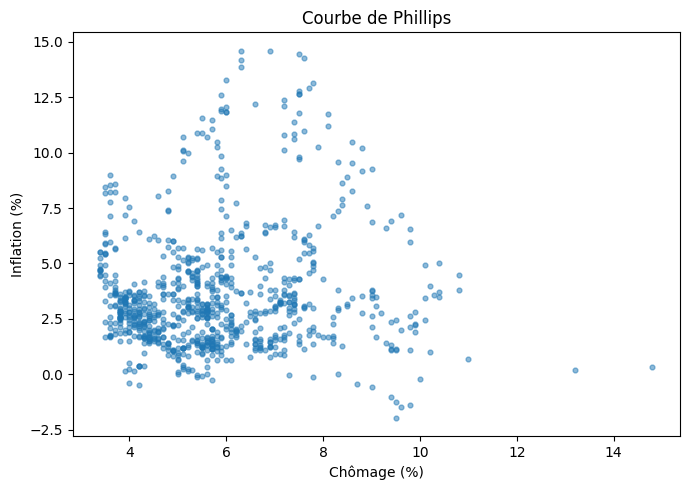

In [35]:
plt.figure(figsize=(7, 5))
plt.scatter(df["chomage"], df["inflation"], alpha=0.5, s=12)
plt.xlabel("Chômage (%)")
plt.ylabel("Inflation (%)")
plt.title("Courbe de Phillips")
plt.tight_layout()
plt.show()

**Description :** la courbe de Phillips relie le chômage (axe x) à l'inflation (axe y). En théorie, la relation est négative : un chômage bas s'accompagne d'une inflation plus forte.

**Interprétation :** sur l'ensemble de la période, la relation n'est pas stable. Dans les années 1970, inflation et chômage montent ensemble (stagflation), ce qui contredit la théorie. La relation dépend donc fortement de la période.

In [36]:
for lag in [0, 6, 12, 18, 24]:
    c = df["taux_directeur"].corr(df["inflation"].shift(lag))
    print(f"Décalage {lag} mois : corrélation = {c:.2f}")

Décalage 0 mois : corrélation = 0.70
Décalage 6 mois : corrélation = 0.70
Décalage 12 mois : corrélation = 0.68
Décalage 18 mois : corrélation = 0.65
Décalage 24 mois : corrélation = 0.60


**Résultat :** la corrélation entre le taux directeur et l'inflation passée est maximale pour un décalage de 0 à 6 mois (corrélation = 0,70). Elle diminue ensuite avec le décalage : 0,68 à 12 mois, 0,65 à 18 mois et 0,60 à 24 mois.

**Interprétation :** le taux directeur est surtout lié à l'inflation récente (du même mois ou d'il y a quelques mois), et beaucoup moins à l'inflation plus ancienne. Cela suggère que la Fed réagit assez rapidement à l'inflation, sans long retard. Les corrélations restent toutefois élevées (au moins 0,60) même à 24 mois, car l'inflation et le taux directeur évoluent lentement et de façon persistante. Il faut donc rester prudent : ce calcul montre une association, pas l'effet du taux directeur sur l'inflation.

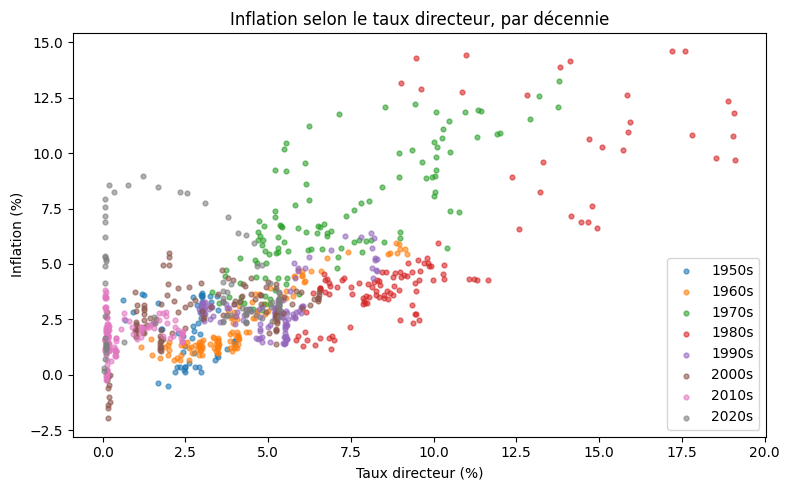

In [37]:
df["decennie"] = (df.index.year // 10) * 10

plt.figure(figsize=(8, 5))
for d, g in df.groupby("decennie"):
    plt.scatter(g["taux_directeur"], g["inflation"], alpha=0.6, s=12, label=f"{d}s")
plt.legend()
plt.xlabel("Taux directeur (%)")
plt.ylabel("Inflation (%)")
plt.title("Inflation selon le taux directeur, par décennie")
plt.tight_layout()
plt.show()

In [38]:
# Pics et creux
print("Inflation max :", round(df["inflation"].max(), 1), "% en", df["inflation"].idxmax().strftime("%Y-%m"))
print("Inflation min :", round(df["inflation"].min(), 1), "% en", df["inflation"].idxmin().strftime("%Y-%m"))
print("Chômage max   :", round(df["chomage"].max(), 1), "% en", df["chomage"].idxmax().strftime("%Y-%m"))
print("Taux directeur max :", round(df["taux_directeur"].max(), 1), "% en", df["taux_directeur"].idxmax().strftime("%Y-%m"))

# Situation actuelle
print("\nDernière date :", df.index[-1].strftime("%Y-%m"))
print(df[["inflation", "chomage", "taux_directeur", "taux_reel"]].iloc[-1].round(2))

# Meilleur décalage
corrs = {lag: df["taux_directeur"].corr(df["inflation"].shift(lag)) for lag in range(0, 37)}
best = max(corrs, key=corrs.get)
print(f"\nMeilleur décalage : {best} mois (corrélation = {corrs[best]:.2f})")

# Corrélation par décennie
print("\nCorrélation taux directeur / inflation par décennie :")
print(df.groupby("decennie").apply(lambda g: g["taux_directeur"].corr(g["inflation"])).round(2))

Inflation max : 14.6 % en 1980-03
Inflation min : -2.0 % en 2009-07
Chômage max   : 14.8 % en 2020-04
Taux directeur max : 19.1 % en 1981-06

Dernière date : 2026-10


KeyError: "['taux_reel'] not in index"

**Résultat :** la corrélation entre le taux directeur et l'inflation passée est maximale pour un décalage de 1 mois (corrélation = 0,70). Elle diminue ensuite lentement : 0,68 à 12 mois, 0,65 à 18 mois et 0,60 à 24 mois.  
 **Interprétation :** la relation entre inflation et taux directeur n'est pas la même selon les époques. Corrélations par décennie : 1950 : −0,06 ; 1960 : 0,93 ; 1970 : 0,78 ; 1980 : 0,77 ; 1990 : 0,53 ; 2000 : 0,53 ; 2010 : 0,19 ; 2020 : −0,14. La relation est la plus forte dans les années 1960 (0,93) et très forte dans les années 1970-1980. Elle s'affaiblit ensuite et devient proche de zéro ou négative dans les années 1950 et 2020. Dans les années 2020, la Fed est restée à zéro alors que l'inflation montait, puis a relevé ses taux alors que l'inflation baissait : les deux séries ne bougent plus ensemble.

## Conclusion

1. **Rôle de la Fed :** la Fed relève son taux directeur quand l'inflation augmente (années 1970-1980, 2022) et le baisse en cas de crise (2008, 2020). Le taux directeur a atteint 19,1 % en juin 1981, au plus fort de la lutte contre l'inflation.

2. **Relation avec l'inflation :** la corrélation entre inflation et taux directeur est positive (0,70). Elle est maximale pour un décalage de 1 mois, ce qui montre que la Fed réagit assez rapidement à l'inflation observée.

3. **Coût de la lutte contre l'inflation :** après la hausse des taux de 1980-1981, l'inflation baisse mais le chômage monte à environ 10,8 % en 1982. Lutter contre l'inflation a un coût en emplois.

4. **Relation instable :** la courbe de Phillips et l'analyse par décennie montrent que les relations changent selon l'époque. La corrélation est de 0,93 dans les années 1960, 0,78 dans les années 1970, mais seulement 0,19 dans les années 2010 et −0,14 dans les années 2020.

5. **Situation actuelle :** en octobre 2026, l'inflation est de 4,1 %, le chômage de 4,1 % et le taux directeur de 3,9 %, soit un taux réel d'environ −0,2 %. L'inflation reste au-dessus de l'objectif de 2 %.

**Limites :** une corrélation n'est pas une causalité. Nous avons utilisé le CPI alors que la Fed cible le PCE. L'objectif de 2 % n'était pas officiel avant 2012. D'autres facteurs, comme les chocs pétroliers ou la pandémie, expliquent aussi les évolutions.

In [43]:
df.duplicated().sum()

np.int64(0)

In [44]:
df[df.duplicated()]

,cpi,chomage,taux_directeur,inflation,decennie
DATE,,,,,


In [45]:
df.describe()

,cpi,chomage,taux_directeur,inflation,decennie
count,855.000000,855.000000,855.000000,855.000000,855.000000
mean,138.061484,5.795439,4.641053,3.624735,1986.105263
std,89.218851,1.676289,3.527403,2.740419,20.936240
min,26.720000,3.400000,0.050000,-1.958761,1950.000000
25%,43.800000,4.400000,2.015000,1.756933,1970.000000
50%,134.800000,5.500000,4.330000,2.965517,1990.000000
75%,214.334000,6.900000,6.135000,4.392794,2000.000000
max,337.476000,14.800000,19.100000,14.592275,2020.000000


In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 855 entries, 1955-07-01 to 2026-10-01
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   cpi             855 non-null    float64
 1   chomage         855 non-null    float64
 2   taux_directeur  855 non-null    float64
 3   inflation       855 non-null    float64
 4   decennie        855 non-null    int32  
dtypes: float64(4), int32(1)
memory usage: 36.7 KB


In [49]:
print(type(df))

<class 'pandas.core.frame.DataFrame'>


In [50]:
df.head()

,cpi,chomage,taux_directeur,inflation,decennie
DATE,,,,,
1955-07-01,26.76,4.0,1.68,-0.372301,1950
1955-08-01,26.72,4.2,1.96,-0.484171,1950
1955-09-01,26.85,4.1,2.18,0.149198,1950
1955-10-01,26.82,4.3,2.24,0.374251,1950
1955-11-01,26.88,4.2,2.35,0.373413,1950


In [51]:
df.tail()

,cpi,chomage,taux_directeur,inflation,decennie
DATE,,,,,
2026-06-01,332.568,4.2,3.63,3.463531,2020
2026-07-01,332.813,4.1,3.63,3.303856,2020
2026-08-01,334.131,4.1,3.63,3.353016,2020
2026-09-01,336.298,4.2,3.75,3.717251,2020
2026-10-01,337.476,4.1,3.88,4.080556,2020


In [55]:
df[['inflation', 'cpi', 'chomage', 'taux_directeur']].corr()

,inflation,cpi,chomage,taux_directeur
inflation,1.000000,-0.219053,0.088938,0.703608
cpi,-0.219053,1.000000,-0.068221,-0.405839
chomage,0.088938,-0.068221,1.000000,0.061901
taux_directeur,0.703608,-0.405839,0.061901,1.000000


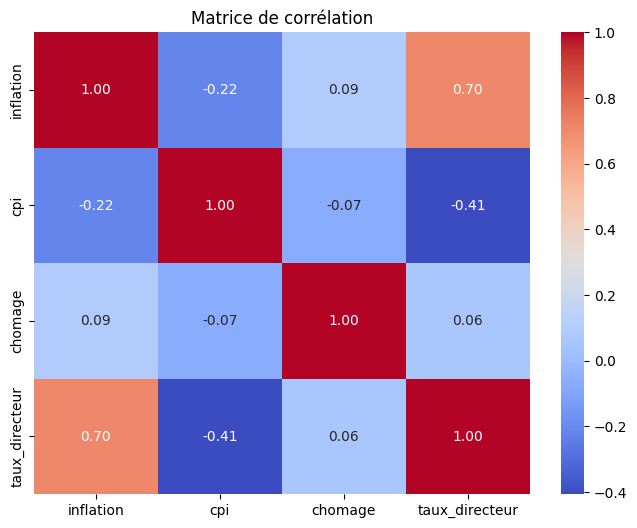

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(df[['inflation', 'cpi', 'chomage', 'taux_directeur']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Matrice de corrélation")
plt.show()

In [57]:
df['inflation_lag1'] = df['inflation'].shift(1)
df['inflation_lag2'] = df['inflation'].shift(2)
df['inflation_lag3'] = df['inflation'].shift(3)

In [58]:
df = df.dropna()

In [59]:
X = df[['inflation_lag1', 'inflation_lag2', 'inflation_lag3',
        'cpi', 'chomage', 'taux_directeur']]

y = df['inflation']

In [60]:
from sklearn.model_selection import train_test_split

split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

In [61]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

MAE: 0.2659671572512012
RMSE: 0.34545577562224977
R²: 0.9696972208362963


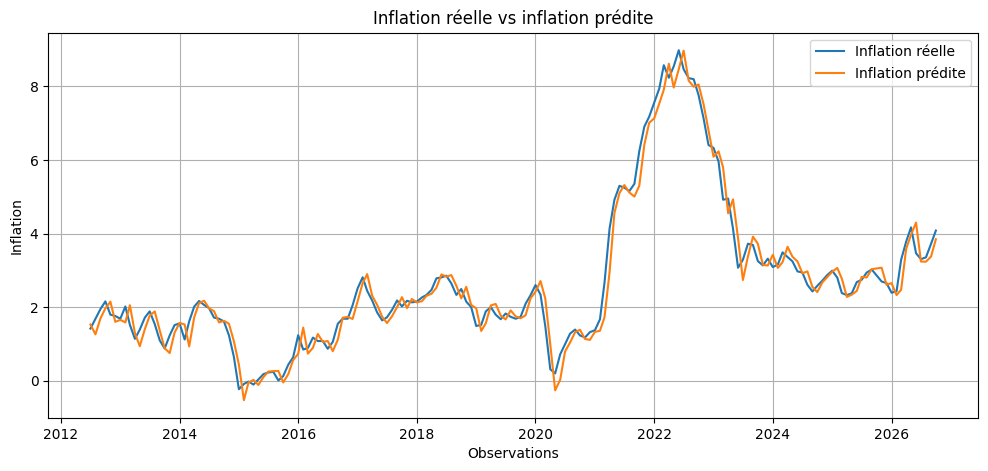

In [63]:
plt.figure(figsize=(12,5))

plt.plot(y_test.index, y_test.values, label="Inflation réelle")
plt.plot(y_test.index, y_pred, label="Inflation prédite")

plt.title("Inflation réelle vs inflation prédite")
plt.xlabel("Observations")
plt.ylabel("Inflation")
plt.legend()
plt.grid()
plt.show()

In [64]:
y_baseline = y_test.index.map(
    df['inflation'].shift(1)
)

mae_baseline = mean_absolute_error(y_test, y_baseline)

print("MAE Baseline :", mae_baseline)
print("MAE Linear Regression :", mean_absolute_error(y_test, y_pred))

MAE Baseline : 0.28191290911419276
MAE Linear Regression : 0.2659671572512012


In [65]:
resultats = pd.DataFrame({
    'Inflation réelle': y_test.values,
    'Inflation prédite': y_pred
})

print(resultats.head(10))

   Inflation réelle  Inflation prédite
0          1.417511           1.527767
1          1.685935           1.260716
2          1.949717           1.695851
3          2.155678           1.966326
4          1.796020           2.148545
5          1.759505           1.599524
6          1.684062           1.655333
7          2.018140           1.584230
8          1.518747           2.051830
9          1.138808           1.291426


In [66]:
resultats.to_csv("resultats_inflation.csv", index=False)

In [67]:
print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² :", r2_score(y_test, y_pred))

MAE : 0.2659671572512012
RMSE : 0.34545577562224977
R² : 0.9696972208362963


In [68]:
coefficients = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient': model.coef_
})

print(coefficients)

         Variable  Coefficient
0  inflation_lag1     1.314882
1  inflation_lag2    -0.312362
2  inflation_lag3    -0.030257
3             cpi    -0.000058
4         chomage    -0.018997
5  taux_directeur     0.018151


In [69]:
y_baseline = df['inflation'].shift(1).loc[y_test.index]

mae_baseline = mean_absolute_error(y_test, y_baseline)

print("MAE Baseline :", mae_baseline)
print("MAE Linear Regression :", mean_absolute_error(y_test, y_pred))

MAE Baseline : 0.28191290911419276
MAE Linear Regression : 0.2659671572512012
